In [ ]:
#Cài đặt hàm schroeder_reverb(x, fs) với các thông số đề xuất
import numpy as np

def comb_filter(x, fs, delay_ms, g):

    D = int(delay_ms * 1e-3 * fs)
    y = np.zeros(len(x) + 10 * D)
    y[:len(x)] = x

    # y[n] = x[n] + g*y[n-D]
    for n in range(D, len(y)):
        y[n] += g * y[n - D]

    return y



def allpass_filter(x, fs, delay_ms, a):

    D = int(delay_ms * 1e-3 * fs)

    y = np.zeros(len(x) + 10 * D)

    y[:len(x)] = -a * x

    # y[n] = -a*x[n] + x[n-D] + a*y[n-D]
    for n in range(D, len(y)):

        if n - D < len(x):
            y[n] += x[n - D] + a * y[n - D]
        else:
            y[n] = a * y[n - D]

    return y


def schroeder_reverb(x, fs):


    RT60 = 2.0

    comb_delays = [
        29.7,
        37.1,
        41.1,
        43.7
    ]

    comb_gains = []

    for td in comb_delays:

        td_seconds = td * 1e-3

        g = 10 ** (-3 * td_seconds / RT60)

        comb_gains.append(g)
    print("Comb delays:", comb_delays)
    print("Comb gains :", comb_gains)


    y_comb1 = comb_filter(
        x, fs,
        comb_delays[0],
        comb_gains[0]
    )

    y_comb2 = comb_filter(
        x, fs,
        comb_delays[1],
        comb_gains[1]
    )

    y_comb3 = comb_filter(
        x, fs,
        comb_delays[2],
        comb_gains[2]
    )

    y_comb4 = comb_filter(
        x, fs,
        comb_delays[3],
        comb_gains[3]
    )


    max_len = max(
        len(y_comb1),
        len(y_comb2),
        len(y_comb3),
        len(y_comb4)
    )

    y_comb = np.zeros(max_len)

    y_comb[:len(y_comb1)] += y_comb1
    y_comb[:len(y_comb2)] += y_comb2
    y_comb[:len(y_comb3)] += y_comb3
    y_comb[:len(y_comb4)] += y_comb4


    y_ap1 = allpass_filter(
        y_comb,
        fs,
        5.0,
        0.7
    )


    y_ap2 = allpass_filter(
        y_ap1,
        fs,
        1.7,
        0.7
    )

    y_reverb = y_ap2

    return y_reverb

In [3]:
#Trộn tỷ lệ tín hiệu mộc (Dry) và tín hiệu vang (Wet)
def mix_dry_wet(x, y_reverb, alpha=0.35):
    N = len(y_reverb)

    x_pad = np.zeros(N)
    x_pad[:len(x)] = x

    y_final = (1 - alpha) * x_pad + alpha * y_reverb

    return y_final

Comb delays: [29.7, 37.1, 41.1, 43.7]
Comb gains : [0.9025057966698159, 0.8797312108127433, 0.8676608460941144, 0.8599040610761105]
Tín hiệu gốc - Dry:


Tín hiệu sau Schroeder Reverb - Dry + Wet:


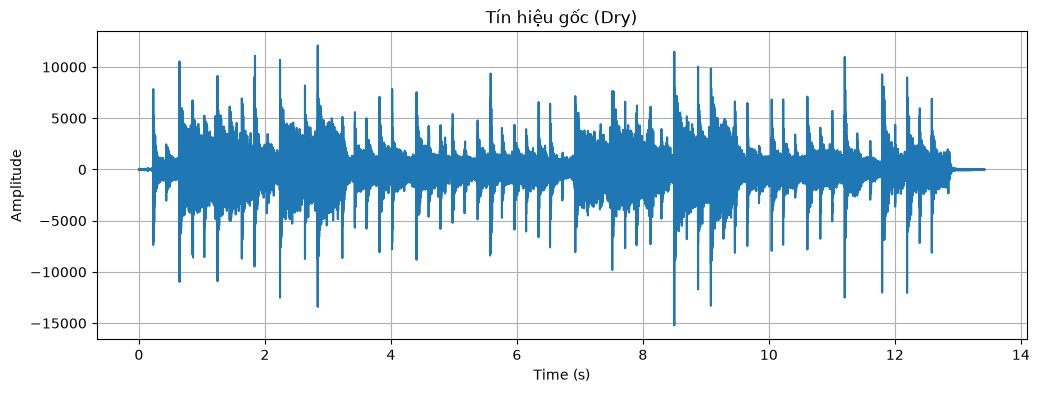

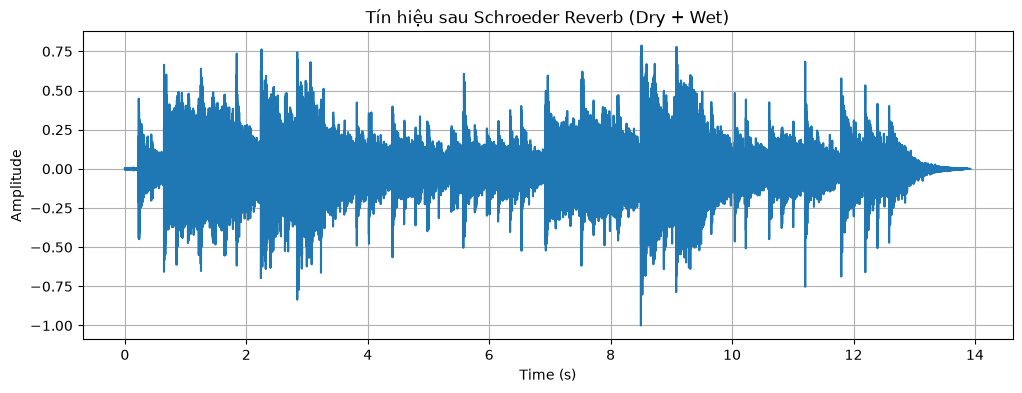

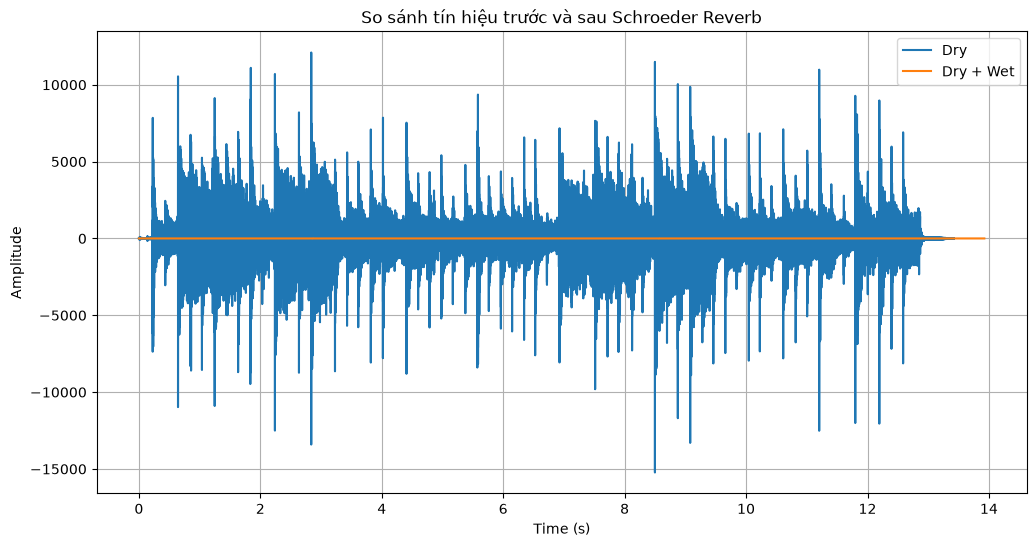

Đã lưu file: guitar_schroeder_reverb.wav


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io.wavfile import read, write
from IPython.display import Audio, display

fs, x = read("guitar1.wav")

x = x.astype(float)
if x.ndim == 2:
    x = np.mean(x, axis=1)
    x = x / np.max(np.abs(x))

y_reverb = schroeder_reverb(x, fs)

y_final = mix_dry_wet(x,y_reverb,alpha=0.35)

y_final = y_final / np.max(np.abs(y_final))

print("Tín hiệu gốc - Dry:")
display(Audio(x, rate=fs))

print("Tín hiệu sau Schroeder Reverb - Dry + Wet:")
display(Audio(y_final, rate=fs))

t_x = np.arange(len(x)) / fs

plt.figure(figsize=(12, 4))
plt.plot(t_x, x)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Tín hiệu gốc (Dry)")
plt.grid()

plt.show()

t_y = np.arange(len(y_final)) / fs

plt.figure(figsize=(12, 4))
plt.plot(t_y, y_final)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Tín hiệu sau Schroeder Reverb (Dry + Wet)")
plt.grid()

plt.show()


plt.figure(figsize=(12, 6))

plt.plot(
    t_x,
    x,
    label="Dry"
)

plt.plot(
    t_y,
    y_final,
    label="Dry + Wet"
)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("So sánh tín hiệu trước và sau Schroeder Reverb")

plt.legend()
plt.grid()

plt.show()


y_int16 = np.int16(y_final * 32767)

write(
    "guitar_schroeder_reverb.wav",
    fs,
    y_int16
)

print("Đã lưu file: guitar_schroeder_reverb.wav")